In [225]:
# Task 5: Decision Trees and Random Forests

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [226]:
# Load the Heart Disease dataset

df = pd.read_csv('/content/heart.csv')

# Display the first five rows
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [227]:
# Inspect dataset structure

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df['target'].value_counts().sort_index())

Dataset shape: (1025, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Missing values:
0

Duplicate rows:
723

Target distribution:
target
0    499
1    526
Name: count, dtype: int64


In [228]:
# Separate features (X) and target (y)

X = df.drop('target', axis=1)
y = df['target']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature shape: (1025, 13)
Target shape: (1025,)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [229]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training features: (820, 13)
Testing features: (205, 13)

Training target distribution:
target
0    0.486585
1    0.513415
Name: proportion, dtype: float64

Testing target distribution:
target
0    0.487805
1    0.512195
Name: proportion, dtype: float64


In [230]:
# Train a Decision Tree Classifier

decision_tree = DecisionTreeClassifier(random_state=42)

decision_tree.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [231]:
# Evaluate Decision Tree performance

y_train_pred_tree = decision_tree.predict(X_train)
y_test_pred_tree = decision_tree.predict(X_test)

train_accuracy_tree = accuracy_score(y_train, y_train_pred_tree)
test_accuracy_tree = accuracy_score(y_test, y_test_pred_tree)

print("Decision Tree Results")
print("----------------------")
print(f"Training Accuracy: {train_accuracy_tree:.4f}")
print(f"Testing Accuracy : {test_accuracy_tree:.4f}")
print(f"Accuracy Gap     : {train_accuracy_tree - test_accuracy_tree:.4f}")

Decision Tree Results
----------------------
Training Accuracy: 1.0000
Testing Accuracy : 0.9854
Accuracy Gap     : 0.0146


In [232]:
# Classification report for the Decision Tree

print(classification_report(y_test, y_test_pred_tree))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99       100
           1       1.00      0.97      0.99       105

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205



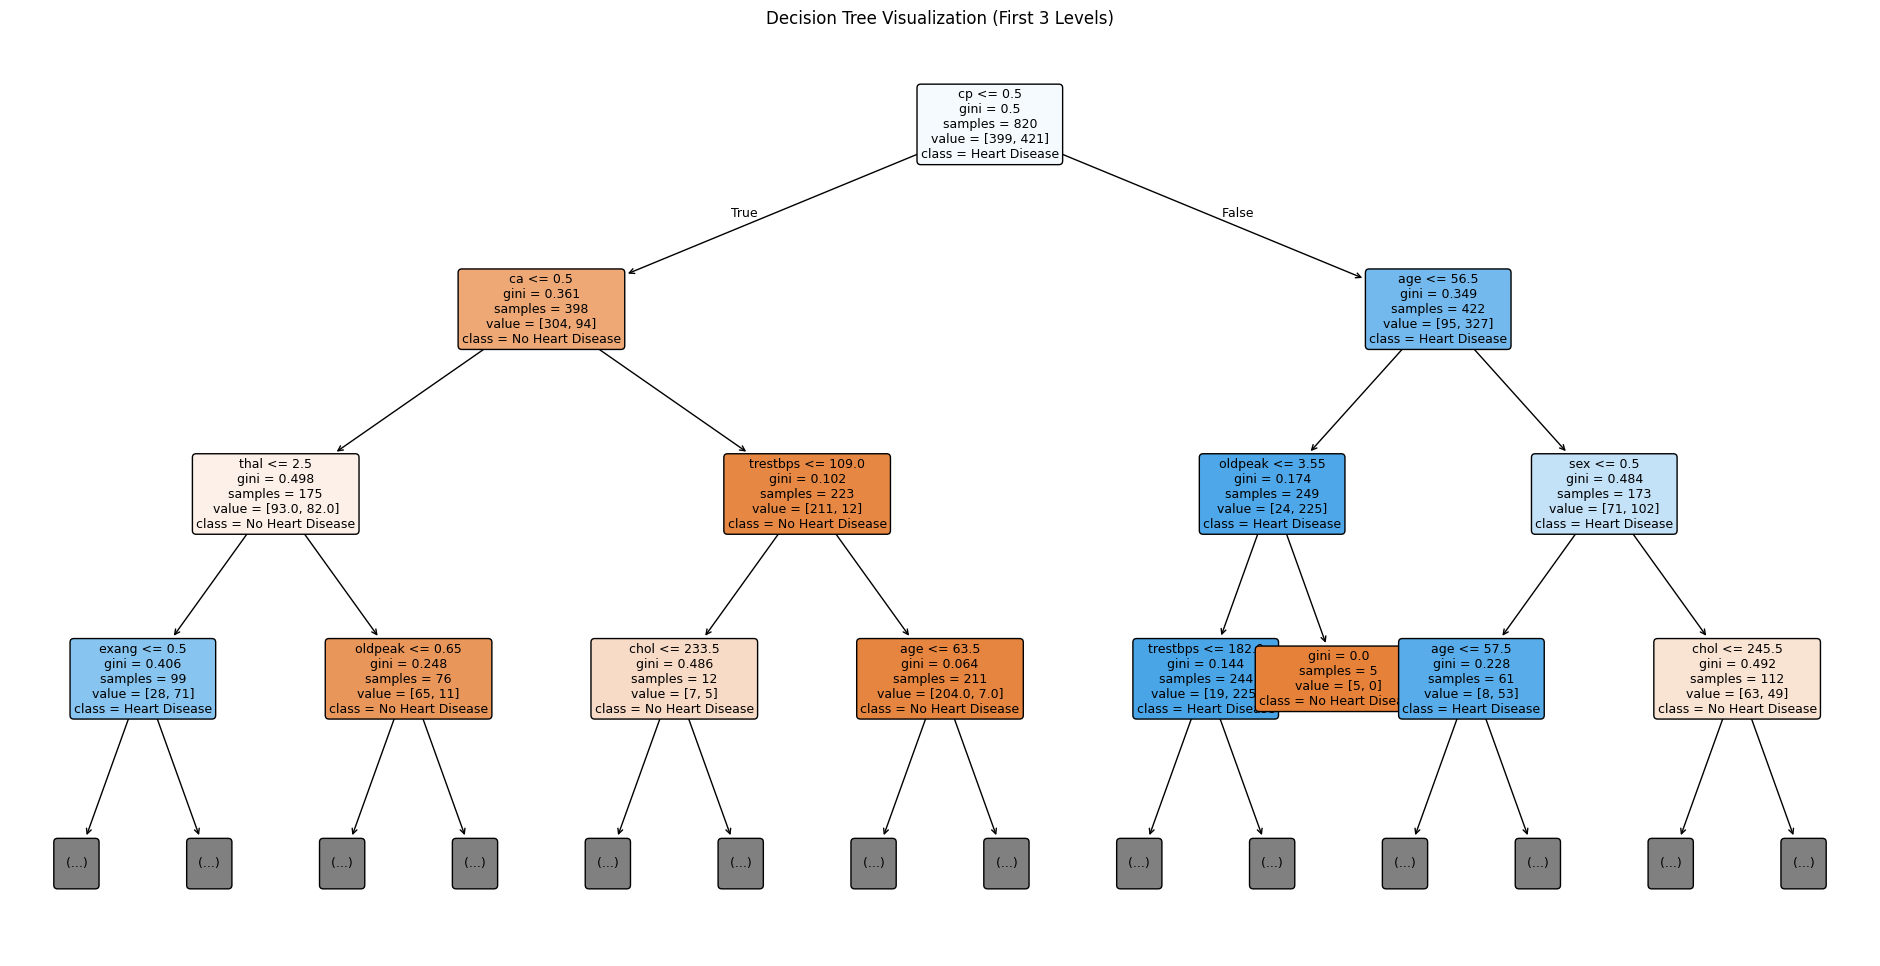

In [233]:
# Visualize the Decision Tree

plt.figure(figsize=(24, 12))

plot_tree(
    decision_tree,
    feature_names=X.columns,
    class_names=['No Heart Disease', 'Heart Disease'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("Decision Tree Visualization (First 3 Levels)")
plt.show()

In [234]:
# Compare Decision Trees with different depths

depths = [2, 3, 4, 5, 10, None]
depth_results = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(
        y_train,
        model.predict(X_train)
    )

    test_acc = accuracy_score(
        y_test,
        model.predict(X_test)
    )

    depth_results.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc
    })

depth_df = pd.DataFrame(depth_results)

print(depth_df.round(4).to_string(index=False))

Max Depth  Training Accuracy  Testing Accuracy
        2             0.7695            0.7220
        3             0.8451            0.8537
        4             0.8854            0.8390
        5             0.9293            0.8732
       10             1.0000            0.9854
     None             1.0000            0.9854


In [235]:
# Train the Random Forest Classifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [236]:
# Predictions from both models

y_test_pred_rf = random_forest.predict(X_test)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, y_test_pred_tree)
rf_accuracy = accuracy_score(y_test, y_test_pred_rf)

# Compare results
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Testing Accuracy": [dt_accuracy, rf_accuracy]
})

print(comparison.round(4).to_string(index=False))

        Model  Testing Accuracy
Decision Tree            0.9854
Random Forest            1.0000


In [237]:
# Feature Importance from Random Forest

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance Ranking:")
print(feature_importance.round(4).to_string(index=False))

Feature Importance Ranking:
 Feature  Importance
      cp      0.1448
 thalach      0.1181
      ca      0.1110
 oldpeak      0.1056
    thal      0.1018
     age      0.0918
    chol      0.0766
   exang      0.0742
trestbps      0.0712
   slope      0.0452
     sex      0.0299
 restecg      0.0192
     fbs      0.0107


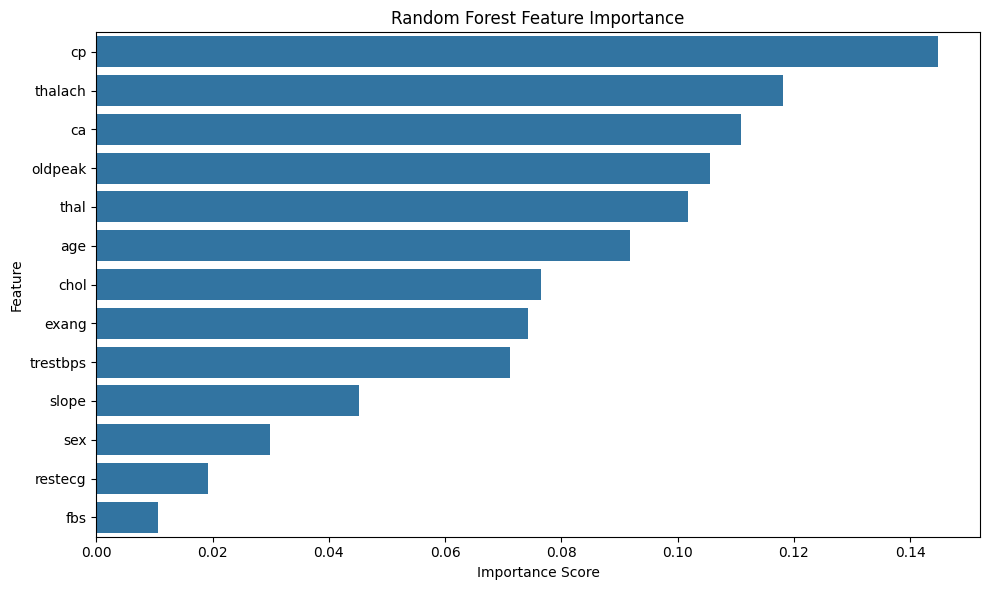

In [238]:
# Visualize Feature Importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [239]:
# 5-Fold Cross-Validation

cv_scores = cross_val_score(
    RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("Cross-validation scores:", cv_scores.round(4))
print(f"Mean CV Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

Cross-validation scores: [1.     1.     1.     1.     0.9854]
Mean CV Accuracy: 0.9971
Standard Deviation: 0.0059


In [240]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Unique rows:", len(df.drop_duplicates()))

Total rows: 1025
Duplicate rows: 723
Unique rows: 302


In [241]:
# Remove duplicate rows
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())

print("\nTarget distribution after removing duplicates:")
print(df_clean["target"].value_counts().sort_index())

Original dataset shape: (1025, 14)
Cleaned dataset shape: (302, 14)
Remaining duplicate rows: 0

Target distribution after removing duplicates:
target
0    138
1    164
Name: count, dtype: int64


In [242]:
# Prepare features and target from the cleaned dataset

X_clean = df_clean.drop("target", axis=1)
y_clean = df_clean["target"]

# Split into training and testing sets
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean,
    y_clean,
    test_size=0.20,
    random_state=42,
    stratify=y_clean
)

print("Training features:", X_train_clean.shape)
print("Testing features:", X_test_clean.shape)

print("\nTraining target distribution:")
print(y_train_clean.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test_clean.value_counts().sort_index())

Training features: (241, 13)
Testing features: (61, 13)

Training target distribution:
target
0    110
1    131
Name: count, dtype: int64

Testing target distribution:
target
0    28
1    33
Name: count, dtype: int64


In [243]:
# Train Decision Tree on the cleaned dataset

decision_tree_clean = DecisionTreeClassifier(random_state=42)

decision_tree_clean.fit(X_train_clean, y_train_clean)

# Make predictions
y_pred_tree_clean = decision_tree_clean.predict(X_test_clean)

# Evaluate
tree_train_acc_clean = accuracy_score(
    y_train_clean,
    decision_tree_clean.predict(X_train_clean)
)

tree_test_acc_clean = accuracy_score(
    y_test_clean,
    y_pred_tree_clean
)

print("Decision Tree — Cleaned Dataset")
print("--------------------------------")
print(f"Training Accuracy: {tree_train_acc_clean:.4f}")
print(f"Testing Accuracy:  {tree_test_acc_clean:.4f}")
print(f"Accuracy Gap:      {tree_train_acc_clean - tree_test_acc_clean:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_clean, y_pred_tree_clean))

Decision Tree — Cleaned Dataset
--------------------------------
Training Accuracy: 1.0000
Testing Accuracy:  0.8033
Accuracy Gap:      0.1967

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.82      0.82      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [244]:
# Train Random Forest on the cleaned dataset

random_forest_clean = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest_clean.fit(X_train_clean, y_train_clean)

# Make predictions
y_pred_rf_clean = random_forest_clean.predict(X_test_clean)

# Evaluate
rf_train_acc_clean = accuracy_score(
    y_train_clean,
    random_forest_clean.predict(X_train_clean)
)

rf_test_acc_clean = accuracy_score(
    y_test_clean,
    y_pred_rf_clean
)

print("Random Forest — Cleaned Dataset")
print("--------------------------------")
print(f"Training Accuracy: {rf_train_acc_clean:.4f}")
print(f"Testing Accuracy:  {rf_test_acc_clean:.4f}")
print(f"Accuracy Gap:      {rf_train_acc_clean - rf_test_acc_clean:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_clean, y_pred_rf_clean))

Random Forest — Cleaned Dataset
--------------------------------
Training Accuracy: 1.0000
Testing Accuracy:  0.7541
Accuracy Gap:      0.2459

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.71      0.73        28
           1       0.76      0.79      0.78        33

    accuracy                           0.75        61
   macro avg       0.75      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61



In [245]:
# Compare models on the cleaned dataset

clean_comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Training Accuracy": [
        tree_train_acc_clean,
        rf_train_acc_clean
    ],
    "Testing Accuracy": [
        tree_test_acc_clean,
        rf_test_acc_clean
    ],
    "Accuracy Gap": [
        tree_train_acc_clean - tree_test_acc_clean,
        rf_train_acc_clean - rf_test_acc_clean
    ]
})

print("Model Comparison — Cleaned Dataset")
print(clean_comparison.round(4).to_string(index=False))

Model Comparison — Cleaned Dataset
        Model  Training Accuracy  Testing Accuracy  Accuracy Gap
Decision Tree                1.0            0.8033        0.1967
Random Forest                1.0            0.7541        0.2459


In [222]:
# 5-Fold Cross-Validation on the Cleaned Dataset

rf_cv_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

cv_scores_clean = cross_val_score(
    rf_cv_model,
    X_clean,
    y_clean,
    cv=5,
    scoring="accuracy"
)

print("Cross-validation scores:", cv_scores_clean.round(4))
print(f"Mean CV Accuracy: {cv_scores_clean.mean():.4f}")
print(f"Standard Deviation: {cv_scores_clean.std():.4f}")

Cross-validation scores: [0.8689 0.8197 0.8833 0.7667 0.7667]
Mean CV Accuracy: 0.8210
Standard Deviation: 0.0492


In [223]:
# Feature Importance — Cleaned Random Forest

feature_importance_clean = pd.DataFrame({
    "Feature": X_clean.columns,
    "Importance": random_forest_clean.feature_importances_
})

feature_importance_clean = feature_importance_clean.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance Ranking — Cleaned Dataset")
print(feature_importance_clean.round(4).to_string(index=False))

Feature Importance Ranking — Cleaned Dataset
 Feature  Importance
      cp      0.1663
 thalach      0.1287
      ca      0.1094
    thal      0.0997
 oldpeak      0.0931
     age      0.0868
   exang      0.0728
    chol      0.0709
trestbps      0.0701
     sex      0.0375
   slope      0.0315
 restecg      0.0240
     fbs      0.0091


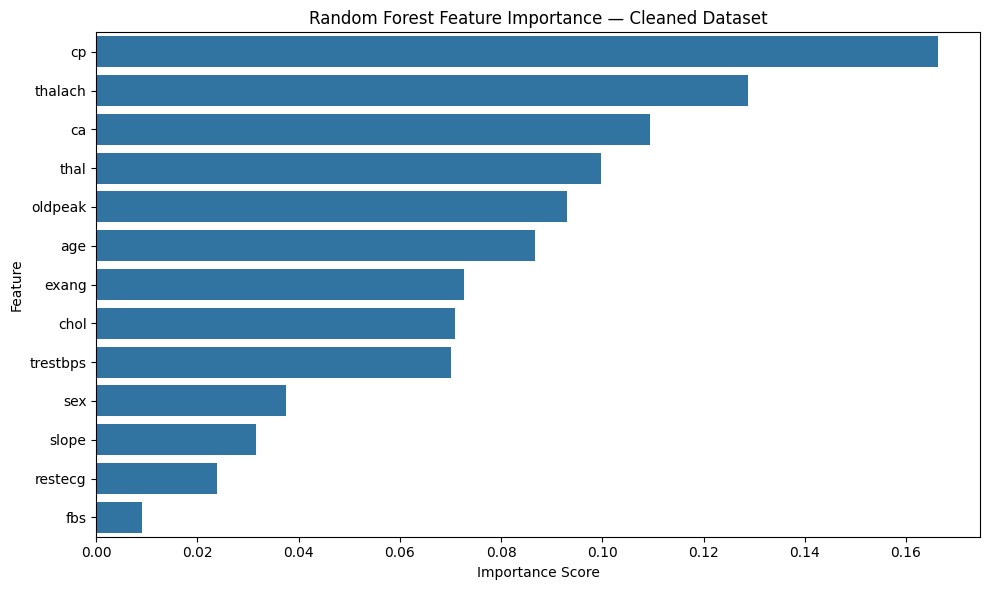

In [224]:
# Plot Feature Importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_clean,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance — Cleaned Dataset")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()